<a href="https://colab.research.google.com/github/Bigulac/Modelling-of-Dynamical-Systems-Mini-Project/blob/main/Modelling_of_Dynamical_Systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Question 1.4

Ellipse      max error 1.54e-07 um | max |u| 0.62 V | max |i| 0.040 A
Wine bottle  max error 1.17e-07 um | max |u| 2.69 V | max |i| 0.609 A


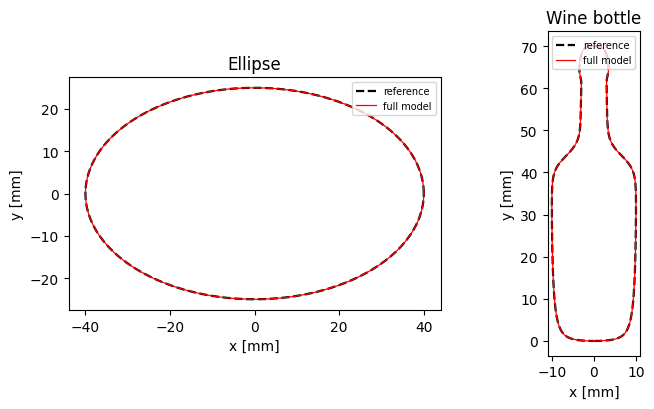

In [ ]:
# Q1.4 – Drawing shapes (feedforward)
import numpy as np, sympy as sp
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
%matplotlib inline
## 1. Parameters (Table 1) and time scaling
rm, Lm, Rm, Km, Jm, m = 6e-3, 1e-3, 2.0, 0.05, 2e-6, 0.4
mur, mulx, muly = 1e-5, 2.0, 2.0
Jeq = Jm + 2*m*rm**2
a = mur + rm**2*(mulx + muly);  c = rm**2*(mulx - muly)
bx = mur + 2*rm**2*mulx;        by = mur + 2*rm**2*muly
T, mm = 4.0, 1e-3

# smooth rest-to-rest time scaling, one lap in T seconds
t = sp.symbols('t')
tau = t/T
phi = 2*sp.pi*(10*tau**3 - 15*tau**4 + 6*tau**5)
## 2. The two shapes
# ellipse
ell = (40*mm*sp.cos(phi), 25*mm*sp.sin(phi))

# wine bottle: y goes 0 -> H -> 0 once per lap, x = half-width(y) * sin(phi)
H, R, r, f = 70*mm, 10*mm, 3.2*mm, 4.0*mm      # height, body, neck, lip half-widths
y_sh, d_sh, y_lip, d_lip = 44*mm, 3.5*mm, 63*mm, 1.2*mm
k = 2.5                                         # flattens base and mouth
step = lambda y, c0, d: (1 + sp.tanh((y - c0)/d))/2
yb = H/2*(1 - sp.tanh(k*sp.cos(phi))/sp.tanh(k))
wb = R + (r - R)*step(yb, y_sh, d_sh) + (f - r)*step(yb, y_lip, d_lip)
bottle = (wb*sp.sin(phi), yb)
## 3. Feedforward voltage and simulation of the full model
def u_ff(q, b):
    # eq. (ff): needs the 1st, 2nd and 3rd time derivative of the reference
    d1, d2, d3 = (sp.diff(q, t, n) for n in (1, 2, 3))
    return (Lm*Jeq*d3 + (Lm*b + Rm*Jeq)*d2 + (Rm*b + Km**2)*d1)/(rm*Km)

def to_fun(expr):
    # cse=True keeps the big derivative expressions fast to evaluate;
    # works for a single time and for arrays
    g = sp.lambdify(t, expr, modules='numpy', cse=True)
    return lambda tt: g(tt)*np.ones_like(tt)

def run(shape):
    xr, yr = shape
    fx, fy = to_fun(xr), to_fun(yr)
    fux, fuy = to_fun(u_ff(xr, bx)), to_fun(u_ff(yr, by))

    def rhs(s_t, s):                                  # full 6-state model
        thl, thr, wl, wr, il, ir = s
        ux, uy = fux(s_t), fuy(s_t)                   # exact voltage, no interpolation
        ul, ur = (ux + uy)/2, (ux - uy)/2
        return [wl, wr,
                (Km*il - a*wl - c*wr)/Jeq,
                (Km*ir - c*wl - a*wr)/Jeq,
                (ul - Rm*il - Km*wl)/Lm,
                (ur - Rm*ir - Km*wr)/Lm]

    x0, y0 = float(fx(0.)), float(fy(0.))
    s0 = [(x0 + y0)/(2*rm), (x0 - y0)/(2*rm), 0, 0, 0, 0]
    tt = np.linspace(0, T, 4001)
    sol = solve_ivp(rhs, [0, T], s0, t_eval=tt, method='Radau',
                    rtol=1e-10, atol=1e-14)
    x = rm*(sol.y[0] + sol.y[1]);  y = rm*(sol.y[0] - sol.y[1])
    xr_, yr_ = fx(tt), fy(tt)
    UX, UY = fux(tt), fuy(tt)
    return dict(t=tt, xr=xr_, yr=yr_, x=x, y=y,
                err=np.hypot(x - xr_, y - yr_).max(),
                umax=np.abs(np.r_[(UX + UY)/2, (UX - UY)/2]).max(),
                imax=np.abs(sol.y[4:]).max())

res = {"Ellipse": run(ell), "Wine bottle": run(bottle)}
for name, d in res.items():
    print(f"{name:12s} max error {d['err']*1e6:.2e} um | max |u| {d['umax']:.2f} V | max |i| {d['imax']:.3f} A")
## 4. Figure (saved as `fig_paths.png`)
fig, axs = plt.subplots(1, 2, figsize=(8, 4.2))
for ax, (name, d) in zip(axs, res.items()):
    ax.plot(d['xr']/mm, d['yr']/mm, 'k--', lw=1.6, label='reference')
    ax.plot(d['x']/mm,  d['y']/mm,  'r',   lw=0.9, label='full model')
    ax.set_aspect('equal'); ax.set_title(name)
    ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]')
    ax.legend(loc='upper right', fontsize=7)
plt.tight_layout()
plt.savefig('fig_paths.png', dpi=200)
plt.show()


### Question 2.1

step  input      state       output
   0  -          PRINTING    print object, heater on
   1  -          PRINTING    print object, heater on
   2  C,F        STOP        stop printing, store (xp, yp)
   3  C          STOP        stop printing, store (xp, yp)
   4  saved      MOVE        move head to wipe tower (0, 0)
   5  arrived    WIPE        wipe excess filament
   6  F          WIPE        wipe excess filament
   7  -          WIPE        wipe excess filament
   8  wiped      NOZZLE OFF  heater off
   9  off        LOAD        load new filament
  10  loaded     NOZZLE ON   heater on, wait for print temperature
  11  -          NOZZLE ON   heater on, wait for print temperature
  12  -          NOZZLE ON   heater on, wait for print temperature
  13  hot        RESUME      move back to (xp, yp), continue printing
  14  back       PRINTING    print object, heater on
  15  C          STOP        stop printing, store (xp, yp)


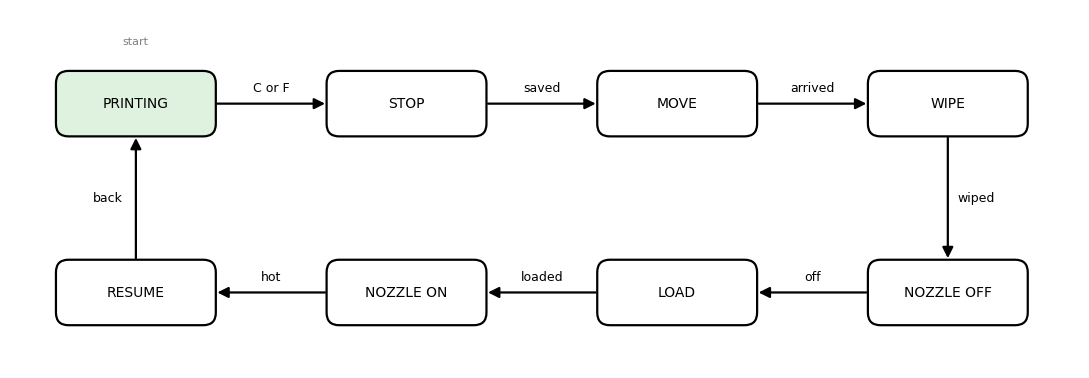

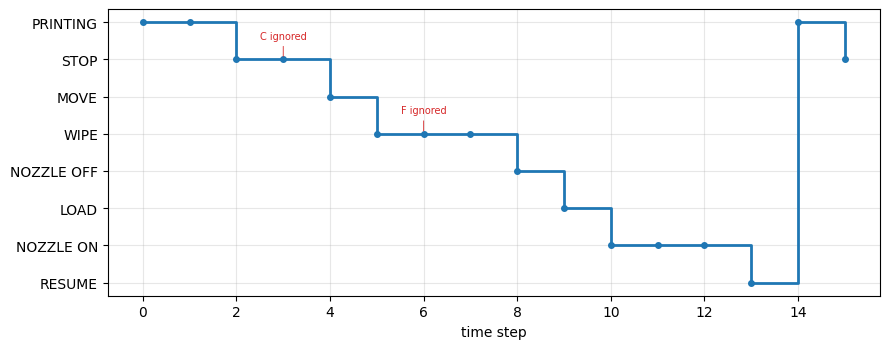

In [ ]:
# Q2.1 – Filament replacement FSM
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
%matplotlib inline
## 1. The machine: output function λ and transition function δ
# state -> output (what the printer does); this is lambda(s)
OUTPUT = {
    "PRINTING":   "print object, heater on",
    "STOP":       "stop printing, store (xp, yp)",
    "MOVE":       "move head to wipe tower (0, 0)",
    "WIPE":       "wipe excess filament",
    "NOZZLE OFF": "heater off",
    "LOAD":       "load new filament",
    "NOZZLE ON":  "heater on, wait for print temperature",
    "RESUME":     "move back to (xp, yp), continue printing",
}

# (state, input) -> next state; this is delta.
# Every state has exactly one outgoing arrow; "C" and "F" both leave PRINTING.
DELTA = {
    ("PRINTING",   "C"):       "STOP",
    ("PRINTING",   "F"):       "STOP",
    ("STOP",       "saved"):   "MOVE",
    ("MOVE",       "arrived"): "WIPE",
    ("WIPE",       "wiped"):   "NOZZLE OFF",
    ("NOZZLE OFF", "off"):     "LOAD",
    ("LOAD",       "loaded"):  "NOZZLE ON",
    ("NOZZLE ON",  "hot"):     "RESUME",
    ("RESUME",     "back"):    "PRINTING",
}

class FilamentFSM:
    def __init__(self):
        self.state = "PRINTING"            # start state s0

    def step(self, inputs):
        """Apply a set of simultaneous inputs, e.g. {"C", "F"}.
        Inputs that do not match the outgoing arrow of the current state
        are ignored, so the machine just stays where it is."""
        for s in inputs:
            nxt = DELTA.get((self.state, s))
            if nxt is not None:
                self.state = nxt
                break                       # one transition per time step
        return OUTPUT[self.state]
## 2. Test run
# one input set per time step
run = [
    set(),                 # normal printing
    {"C", "F"},            # colour change and spool finished at the same time
    {"C"},                 # extra request during STOP: ignored
    {"saved"}, {"arrived"},
    {"F"},                 # request during WIPE: ignored
    set(),                 # wiping not done yet: stay in WIPE
    {"wiped"}, {"off"}, {"loaded"},
    set(), set(),          # nozzle still heating: stay in NOZZLE ON
    {"hot"}, {"back"},
    {"C"},                 # a new request is accepted again in PRINTING
]

m = FilamentFSM()
history = [m.state]
print(f"{'step':>4}  {'input':<10} {'state':<11} output")
print(f"{0:>4}  {'-':<10} {m.state:<11} {OUTPUT[m.state]}")
for k, inp in enumerate(run, 1):
    out = m.step(inp)
    history.append(m.state)
    print(f"{k:>4}  {','.join(sorted(inp)) or '-':<10} {m.state:<11} {out}")
## 3. Figure 1: state diagram (saved as `fig_fsm.png`)
# same layout as the TikZ figure: top row left->right, bottom row right->left
pos = {"PRINTING": (0, 0), "STOP": (4.3, 0), "MOVE": (8.6, 0), "WIPE": (12.9, 0),
       "NOZZLE OFF": (12.9, -3), "LOAD": (8.6, -3), "NOZZLE ON": (4.3, -3), "RESUME": (0, -3)}
w, h = 2.5, 1.0

fig, ax = plt.subplots(figsize=(11, 4.2))
for name, (x, y) in pos.items():
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.2",
                                fc="#dff2df" if name == "PRINTING" else "white", ec="k", lw=1.6))
    ax.text(x, y, name, ha="center", va="center", fontsize=10)

def arrow(src, dst, label, label_off=(0, 0.25)):
    (x1, y1), (x2, y2) = pos[src], pos[dst]
    if y1 == y2:                         # horizontal arrow between box edges
        s = 1 if x2 > x1 else -1
        p1, p2 = (x1 + s*w/2, y1), (x2 - s*w/2, y2)
    else:                                # vertical arrow
        s = 1 if y2 > y1 else -1
        p1, p2 = (x1, y1 + s*h/2), (x2, y2 - s*h/2)
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=16, lw=1.6, color="k"))
    ax.text((p1[0] + p2[0])/2 + label_off[0], (p1[1] + p2[1])/2 + label_off[1],
            label, ha="center", va="center", fontsize=9)

# the arrows are read off DELTA, so the figure always matches the code
labels = {}
for (s, inp), d in DELTA.items():
    labels.setdefault((s, d), []).append(inp)
for (s, d), inps in labels.items():
    off = (0.45, 0) if pos[s][0] == pos[d][0] and pos[s][1] != pos[d][1] and s == "WIPE" else \
          (-0.45, 0) if pos[s][0] == pos[d][0] else (0, 0.25)
    arrow(s, d, " or ".join(inps), off)

ax.text(0, 0.95, "start", ha="center", fontsize=8, color="gray")
ax.set_xlim(-2, 15); ax.set_ylim(-4.2, 1.5); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig("fig_fsm.png", dpi=200, bbox_inches="tight")
plt.show()
## 4. Figure 2: state over time for the test run (saved as `fig_fsm_run.png`)
order = list(OUTPUT)                       # PRINTING, STOP, ..., RESUME
yidx = [order.index(s) for s in history]
steps = list(range(len(history)))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(steps, yidx, where="post", color="tab:blue", lw=2)
ax.plot(steps, yidx, "o", color="tab:blue", ms=4)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel("time step"); ax.grid(alpha=0.3)

# mark the inputs that were ignored (the machine stayed in its state)
for k, inp in enumerate(run, 1):
    if inp and history[k] == history[k-1]:
        ax.annotate(",".join(sorted(inp)) + " ignored", (k, yidx[k]), xytext=(k, yidx[k] - 0.55),
                    ha="center", fontsize=7, color="tab:red",
                    arrowprops=dict(arrowstyle="-", color="tab:red", lw=0.6))
plt.tight_layout()
plt.savefig("fig_fsm_run.png", dpi=200)
plt.show()

# in Colab: uncomment to download the figures
# from google.colab import files; files.download("fig_fsm.png"); files.download("fig_fsm_run.png")

states: ['q0', 'q0', 'q0', 'q0', 'q1', 'q1', 'q3'] -> accepted: True
(a) 87381 sequences checked, mismatches: 0
(b) 8176 head runs, 4898 accepted, accepted but not at origin: 0


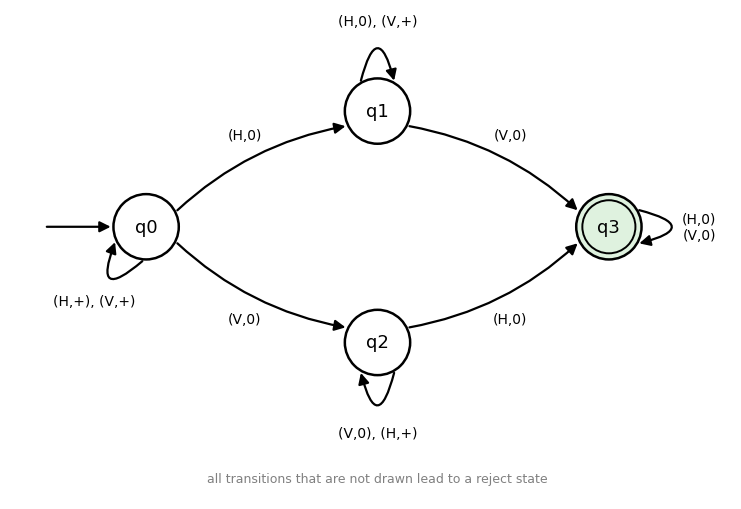

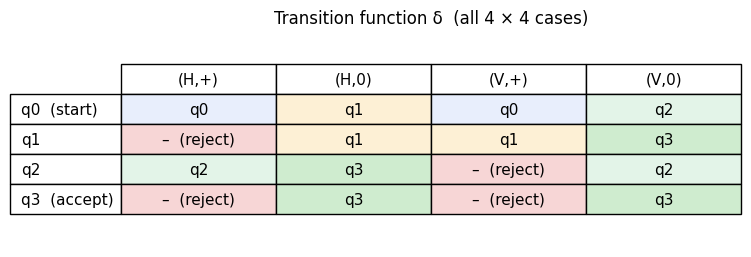

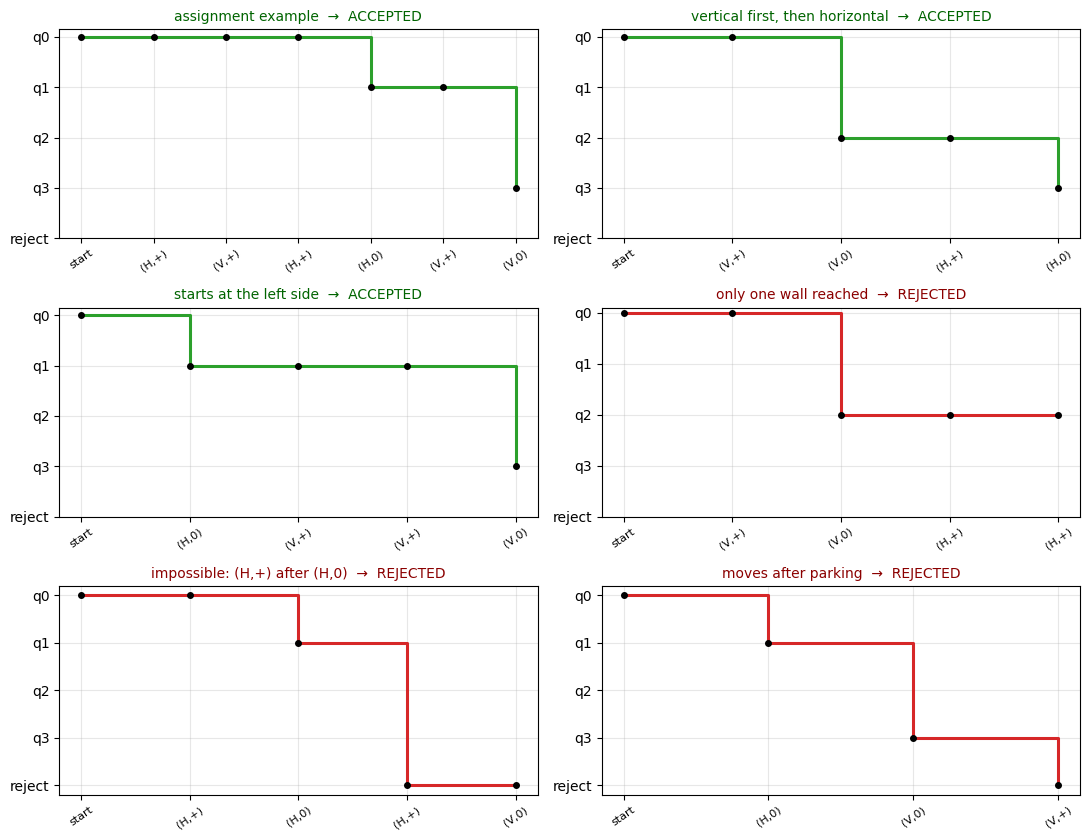

sensor readings: [('H', '+'), ('V', '+'), ('H', '+'), ('H', '0'), ('V', '+'), ('V', '0')] -> accepted: True


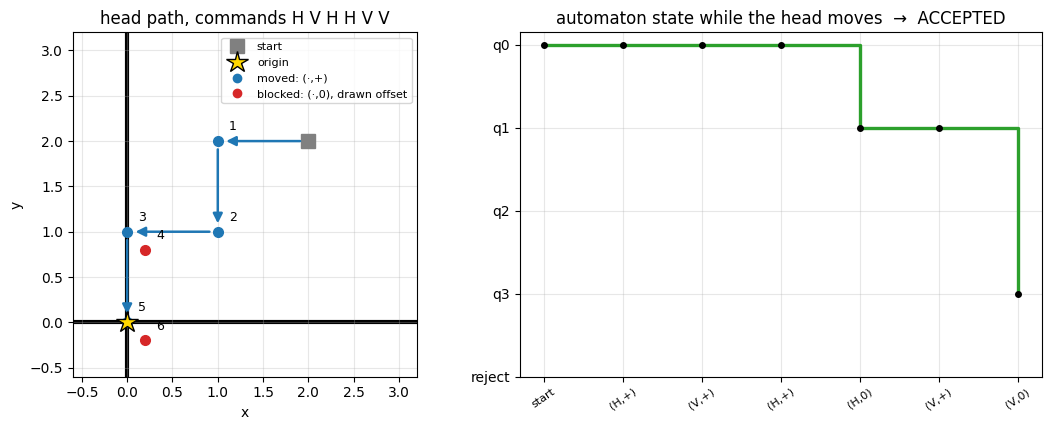

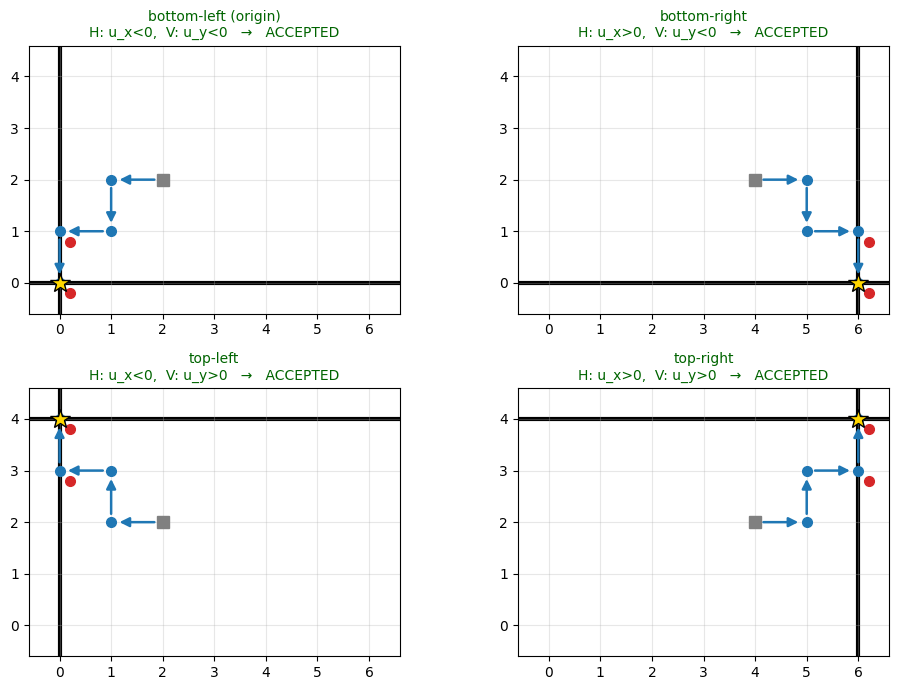

In [ ]:
# Q2.2 – Head-parked detector (automaton)
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
%matplotlib inline
## 1. The automaton
# input symbols: (commanded motion, angular velocity)
SIGMA = [("H", "+"), ("H", "0"), ("V", "+"), ("V", "0")]
STATES = ["q0", "q1", "q2", "q3"]
START, ACCEPT = "q0", {"q3"}
MEANING = {"q0": "no wall reached", "q1": "left side reached",
           "q2": "bottom reached",  "q3": "both reached = parked"}

# (state, symbol) -> next state.  Anything not listed goes to "reject".
DELTA = {
    ("q0", ("H", "+")): "q0", ("q0", ("V", "+")): "q0",
    ("q0", ("H", "0")): "q1", ("q0", ("V", "0")): "q2",

    ("q1", ("H", "0")): "q1", ("q1", ("V", "+")): "q1",
    ("q1", ("V", "0")): "q3",

    ("q2", ("V", "0")): "q2", ("q2", ("H", "+")): "q2",
    ("q2", ("H", "0")): "q3",

    ("q3", ("H", "0")): "q3", ("q3", ("V", "0")): "q3",
}

def trace(seq):
    """List of states visited; stays in 'reject' once entered."""
    q, tr = START, [START]
    for s in seq:
        q = DELTA.get((q, s), "reject") if q != "reject" else "reject"
        tr.append(q)
    return tr

def accepts(seq):
    return trace(seq)[-1] in ACCEPT

# the example from the assignment
ex = [("H","+"), ("V","+"), ("H","+"), ("H","0"), ("V","+"), ("V","0")]
print("states:", trace(ex), "-> accepted:", accepts(ex))
## 2. Verification: every sequence up to length 8, and a simulated head
# (a) compare with an independent definition of the language:
#     both (H,0) and (V,0) occur, and no (H,+) after the first (H,0),
#     no (V,+) after the first (V,0)
def reference(seq):
    hz = vz = False
    for M, m in seq:
        if M == "H":
            if m == "+" and hz: return False
            if m == "0": hz = True
        else:
            if m == "+" and vz: return False
            if m == "0": vz = True
    return hz and vz

n = bad = 0
for L in range(9):
    for seq in itertools.product(SIGMA, repeat=L):
        n += 1; bad += accepts(seq) != reference(seq)
print(f"(a) {n} sequences checked, mismatches: {bad}")

# (b) physical check: a head on a grid that always moves towards the origin.
#     Accepted  =>  the head must really be at the origin.
def simulate(x, y, cmds):
    out = []
    for c in cmds:
        if c == "H":
            if x > 0: x -= 1; out.append(("H", "+"))
            else:             out.append(("H", "0"))
        else:
            if y > 0: y -= 1; out.append(("V", "+"))
            else:             out.append(("V", "0"))
    return x, y, out

runs = accepted = unsound = 0
for x0, y0 in itertools.product(range(4), repeat=2):
    for L in range(9):
        for cmds in itertools.product("HV", repeat=L):
            x, y, out = simulate(x0, y0, cmds)
            runs += 1
            if accepts(out):
                accepted += 1
                unsound += (x, y) != (0, 0)
print(f"(b) {runs} head runs, {accepted} accepted, accepted but not at origin: {unsound}")
## 3. Figure 1 – automaton diagram (`fig_dfa.png`)
pos = {"q0": np.array([0.0, 0.0]), "q1": np.array([3.4, 1.7]),
       "q2": np.array([3.4, -1.7]), "q3": np.array([6.8, 0.0])}
R = 0.48

fig, ax = plt.subplots(figsize=(10, 5.2))
for q, p in pos.items():
    ax.add_patch(Circle(p, R, fc="#dff2df" if q in ACCEPT else "white", ec="k", lw=1.8, zorder=3))
    if q in ACCEPT:
        ax.add_patch(Circle(p, R - 0.09, fc="none", ec="k", lw=1.4, zorder=4))
    ax.text(*p, q, ha="center", va="center", fontsize=13, zorder=5)

# start arrow
ax.add_patch(FancyArrowPatch((-1.5, 0), (-R, 0), arrowstyle="-|>", mutation_scale=16, lw=1.6, color="k"))

def edge(a, b, label, rad, off=0.28):
    d = pos[b] - pos[a]; u = d / np.linalg.norm(d)
    p1, p2 = pos[a] + u * R, pos[b] - u * R
    ax.add_patch(FancyArrowPatch(p1, p2, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>",
                                 mutation_scale=16, lw=1.6, color="k", zorder=2))
    mid = (p1 + p2) / 2; nrm = np.array([-u[1], u[0]])      # left normal
    s = -np.sign(rad) if rad != 0 else 1                     # label on the bulging side
    ax.text(*(mid + s * nrm * (abs(rad) * np.linalg.norm(d) / 2 + off)), label,
            ha="center", va="center", fontsize=10)

def loop(q, ang, label):
    dirv = np.array([np.cos(np.radians(ang)), np.sin(np.radians(ang))])
    A = pos[q] + R * np.array([np.cos(np.radians(ang + 32)), np.sin(np.radians(ang + 32))])
    B = pos[q] + R * np.array([np.cos(np.radians(ang - 32)), np.sin(np.radians(ang - 32))])
    mid = (A + B) / 2; dx, dy = B - A
    ctrl_plus = np.array([mid[0] + dy, mid[1] - dx])        # control point for rad = +1
    rad = 2.0 if np.dot(ctrl_plus - mid, dirv) > 0 else -2.0
    ax.add_patch(FancyArrowPatch(A, B, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>",
                                 mutation_scale=16, lw=1.6, color="k", zorder=2))
    ax.text(*(pos[q] + (R + 0.85) * dirv), label, ha="center", va="center", fontsize=10)

edge("q0", "q1", "(H,0)", -0.15); edge("q0", "q2", "(V,0)", 0.15)
edge("q1", "q3", "(V,0)", -0.15); edge("q2", "q3", "(H,0)", 0.15)
loop("q0", 235, "(H,+), (V,+)"); loop("q1", 90, "(H,0), (V,+)")
loop("q2", -90, "(V,0), (H,+)");  loop("q3", 0, "(H,0)\n(V,0)")

ax.text(3.4, -3.75, "all transitions that are not drawn lead to a reject state",
        ha="center", fontsize=9, color="gray")
ax.set_xlim(-2, 8.6); ax.set_ylim(-4.0, 3.2); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout(); plt.savefig("fig_dfa.png", dpi=200, bbox_inches="tight"); plt.show()
## 4. Figure 2 – complete transition table (`fig_dfa_table.png`)
colors = {"q0": "#e8eefc", "q1": "#fdf0d5", "q2": "#e3f4e8", "q3": "#cfeccf", "reject": "#f7d6d6"}
cols = [f"({M},{m})" for M, m in SIGMA]
cell, cc = [], []
for q in STATES:
    row, crow = [], []
    for s in SIGMA:
        nxt = DELTA.get((q, s), "reject")
        row.append("–  (reject)" if nxt == "reject" else nxt); crow.append(colors[nxt])
    cell.append(row); cc.append(crow)

fig, ax = plt.subplots(figsize=(8, 2.8)); ax.axis("off")
rowlab = [f"{q}{'  (start)' if q == START else ''}{'  (accept)' if q in ACCEPT else ''}" for q in STATES]
tb = ax.table(cellText=cell, cellColours=cc, rowLabels=rowlab, colLabels=cols, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(11); tb.scale(1, 1.8)
ax.set_title("Transition function δ  (all 4 × 4 cases)", fontsize=12)
plt.savefig("fig_dfa_table.png", dpi=200, bbox_inches="tight"); plt.show()
## 5. Figure 3 – state traces of example sequences (`fig_dfa_traces.png`)
examples = {
    "assignment example":            ex,
    "vertical first, then horizontal": [("V","+"),("V","0"),("H","+"),("H","0")],
    "starts at the left side":       [("H","0"),("V","+"),("V","+"),("V","0")],
    "only one wall reached":         [("V","+"),("V","0"),("H","+"),("H","+")],
    "impossible: (H,+) after (H,0)": [("H","+"),("H","0"),("H","+"),("V","0")],
    "moves after parking":           [("H","0"),("V","0"),("V","+")],
}
levels = ["q0", "q1", "q2", "q3", "reject"]
fig, axs = plt.subplots(3, 2, figsize=(11, 8.5))
for ax, (name, seq) in zip(axs.ravel(), examples.items()):
    tr = trace(seq); ok = accepts(seq)
    yy = [levels.index(q) for q in tr]
    ax.step(range(len(yy)), yy, where="post", color="tab:green" if ok else "tab:red", lw=2.2)
    ax.plot(range(len(yy)), yy, "o", color="k", ms=4)
    ax.set_yticks(range(5)); ax.set_yticklabels(levels); ax.invert_yaxis()
    ax.set_xticks(range(len(yy)))
    ax.set_xticklabels(["start"] + [f"({M},{m})" for M, m in seq], rotation=35, fontsize=8)
    ax.set_title(f"{name}  →  {'ACCEPTED' if ok else 'REJECTED'}", fontsize=10,
                 color="darkgreen" if ok else "darkred")
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_dfa_traces.png", dpi=200); plt.show()
## 6. Figure 4 – a simulated head on a grid (`fig_dfa_head.png`)
def move(x, y, cmds, target=(0, 0), size=(5, 4)):
    """Head on a grid. Each command moves one cell towards the target wall of that axis
    unless it is already there; the sensor reads '+' if it moved and '0' if blocked."""
    X, Y = size; tx, ty = target
    sx = 1 if tx > x else -1
    sy = 1 if ty > y else -1
    P, S = [(x, y)], []
    for c in cmds:
        if c == "H":
            if x != tx: x += sx; S.append(("H", "+"))
            else:       S.append(("H", "0"))
        else:
            if y != ty: y += sy; S.append(("V", "+"))
            else:       S.append(("V", "0"))
        P.append((x, y))
    return P, S

cmds = "HVHHVV"                              # the assignment's example, started at (2, 2)
def draw_path(ax, P, S, number=True):
    """Arrows between cells; blue dot = head moved, red dot = blocked (offset so it stays visible)."""
    seen = {}
    for k in range(1, len(P)):
        (x1, y1), (x2, y2) = P[k-1], P[k]
        if (x1, y1) != (x2, y2):
            ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14,
                                         lw=1.8, color="tab:blue", shrinkA=6, shrinkB=6, zorder=4))
        moved = S[k-1][1] == "+"
        n = seen.get((x2, y2), 0) if not moved else 0
        off = np.array([0.0, 0.0]) if moved else np.array([0.2, -0.2]) * (n + 1)
        if not moved: seen[(x2, y2)] = n + 1
        ax.plot(x2 + off[0], y2 + off[1], "o", color="tab:blue" if moved else "tab:red", ms=7, zorder=6)
        if number: ax.text(x2 + off[0] + 0.12, y2 + off[1] + 0.12, str(k), fontsize=9, zorder=7)

P, S = move(2, 2, cmds)
print("sensor readings:", S, "-> accepted:", accepts(S))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
a1.axvline(0, color="k", lw=3, zorder=1); a1.axhline(0, color="k", lw=3, zorder=1)          # left and bottom wall
draw_path(a1, P, S)
a1.plot(*P[0], "s", color="gray", ms=10, label="start")
a1.plot(0, 0, "*", color="gold", ms=16, mec="k", label="origin", zorder=6)
a1.plot([], [], "o", color="tab:blue", label="moved: (·,+)"); a1.plot([], [], "o", color="tab:red", label="blocked: (·,0), drawn offset")
a1.set_xlim(-0.6, 3.2); a1.set_ylim(-0.6, 3.2); a1.set_aspect("equal"); a1.grid(alpha=0.3)
a1.set_title("head path, commands " + " ".join(cmds)); a1.legend(fontsize=8, loc="upper right")
a1.set_xlabel("x"); a1.set_ylabel("y")

tr = trace(S); yy = [levels.index(q) for q in tr]
a2.step(range(len(yy)), yy, where="post", color="tab:green", lw=2.4); a2.plot(range(len(yy)), yy, "ko", ms=4)
a2.set_yticks(range(5)); a2.set_yticklabels(levels); a2.invert_yaxis()
a2.set_xticks(range(len(yy))); a2.set_xticklabels(["start"] + [f"({M},{m})" for M, m in S], rotation=35, fontsize=8)
a2.set_title("automaton state while the head moves  →  ACCEPTED"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_dfa_head.png", dpi=200); plt.show()
## 7. Figure 5 – the same automaton for all four corners (`fig_dfa_corners.png`)
size = (6, 4)
corners = {  # target corner: (tx, ty), start two cells away from each wall, label rule
    "bottom-left (origin)": ((0, 0),       (2, 2), "H: u_x<0,  V: u_y<0"),
    "bottom-right":         ((size[0], 0), (size[0]-2, 2), "H: u_x>0,  V: u_y<0"),
    "top-left":             ((0, size[1]), (2, size[1]-2), "H: u_x<0,  V: u_y>0"),
    "top-right":            (size,         (size[0]-2, size[1]-2), "H: u_x>0,  V: u_y>0"),
}
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for ax, (name, ((tx, ty), (x0, y0), rule)) in zip(axs.ravel(), corners.items()):
    P, S = move(x0, y0, "HVHHVV", target=(tx, ty), size=size)   # same command pattern
    ok = accepts(S)
    ax.axvline(tx, color="k", lw=3, zorder=1); ax.axhline(ty, color="k", lw=3, zorder=1)
    draw_path(ax, P, S, number=False)
    ax.plot(*P[0], "s", color="gray", ms=9); ax.plot(tx, ty, "*", color="gold", ms=15, mec="k", zorder=6)
    ax.set_xlim(-0.6, size[0] + 0.6); ax.set_ylim(-0.6, size[1] + 0.6); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_title(f"{name}\n{rule}   →   {'ACCEPTED' if ok else 'REJECTED'}", fontsize=10,
                 color="darkgreen" if ok else "darkred")
plt.tight_layout(); plt.savefig("fig_dfa_corners.png", dpi=200); plt.show()

